<a href="https://colab.research.google.com/github/Prajakta901/contri/blob/main/cutoffs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/cutoffs.csv')



In [ ]:
print(f'Number of Rows: {df.shape[0]}')
print(f'Number of Columns: {df.shape[1]}')
print('\nColumns:', list(df.columns))

Number of Rows: 50755
Number of Columns: 15

Columns: ['university_id', 'university', 'year', 'programme_id', 'programme', 'college', 'variant', 'round', 'category', 'seat_type', 'figure', 'figure_kind', 'basis', 'source_id', 'source_page']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84210 entries, 0 to 84209
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   university_id  84210 non-null  object 
 1   university     84210 non-null  object 
 2   year           84210 non-null  int64  
 3   programme_id   84210 non-null  object 
 4   programme      84210 non-null  object 
 5   college        75812 non-null  object 
 6   variant        51224 non-null  object 
 7   round          84210 non-null  object 
 8   category       84210 non-null  object 
 9   seat_type      84210 non-null  object 
 10  figure         84205 non-null  float64
 11  figure_kind    84210 non-null  object 
 12  basis          84210 non-null  object 
 13  source_id      84210 non-null  object 
 14  source_page    68359 non-null  float64
dtypes: float64(2), int64(1), object(12)
memory usage: 9.6+ MB


In [ ]:
print('\n=== Missing Values ===')
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else 'No missing values found.')


=== Missing Values ===
college         6814
variant        12277
round              1
category           1
seat_type          1
figure             1
figure_kind        1
basis              1
source_id          1
source_page    15852
dtype: int64


In [ ]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
if len(numeric_cols) > 0:
    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        print(f'{col}: {len(outliers)} outliers found')
else:
    print('No numeric columns to analyze for outliers.')

year: 0 outliers found
figure: 6283 outliers found
source_page: 2406 outliers found


In [ ]:
print(df.describe(include='all'))

                   university_id                university          year  \
count                      84210                     84210  84210.000000   
unique                        43                        43           NaN   
top     banaras-hindu-university  Banaras Hindu University           NaN   
freq                       35878                     35878           NaN   
mean                         NaN                       NaN   2025.374706   
std                          NaN                       NaN      0.672381   
min                          NaN                       NaN   2024.000000   
25%                          NaN                       NaN   2025.000000   
50%                          NaN                       NaN   2025.000000   
75%                          NaN                       NaN   2026.000000   
max                          NaN                       NaN   2026.000000   

                                programme_id  \
count                                  

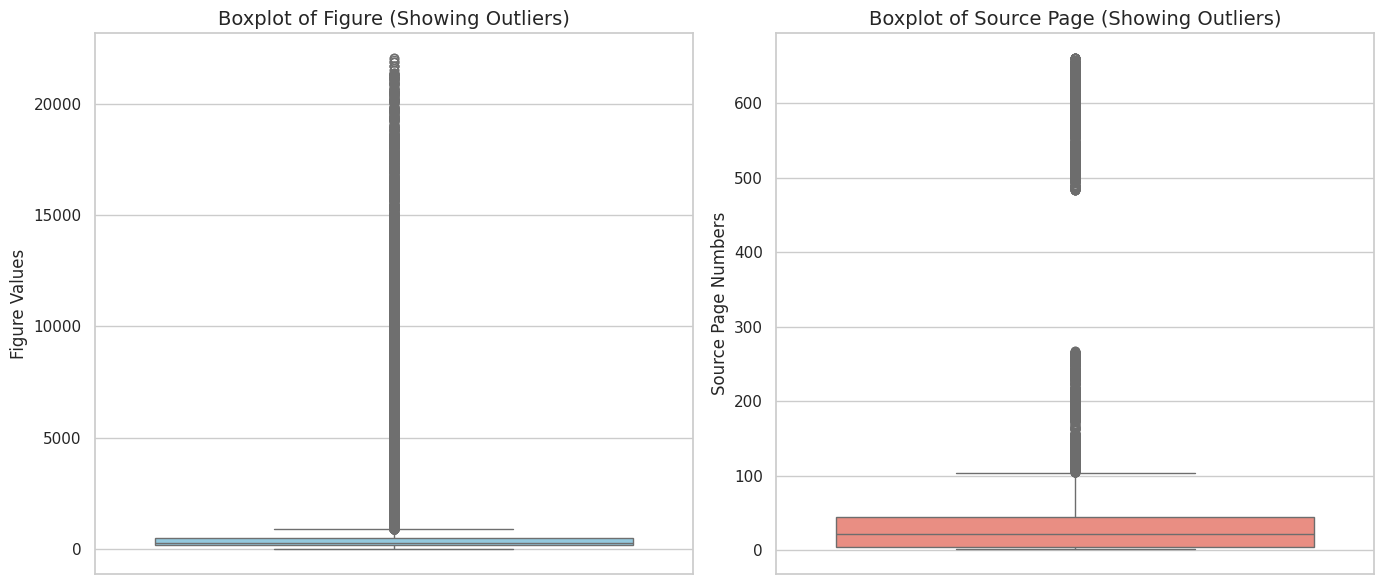

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style of the plots
sns.set_theme(style="whitegrid")

# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Boxplot for 'figure'
sns.boxplot(data=df, y='figure', ax=axes[0], color='skyblue')
axes[0].set_title('Boxplot of Figure (Showing Outliers)', fontsize=14)
axes[0].set_ylabel('Figure Values', fontsize=12)

# Boxplot for 'source_page'
sns.boxplot(data=df, y='source_page', ax=axes[1], color='salmon')
axes[1].set_title('Boxplot of Source Page (Showing Outliers)', fontsize=14)
axes[1].set_ylabel('Source Page Numbers', fontsize=12)

plt.tight_layout()
plt.show()

=== Rank Distribution Summary ===
count     6061.000000
mean      6923.553374
std       5419.704431
min         39.000000
25%       2264.000000
50%       5435.000000
75%      10958.000000
max      22049.000000
Name: figure, dtype: float64


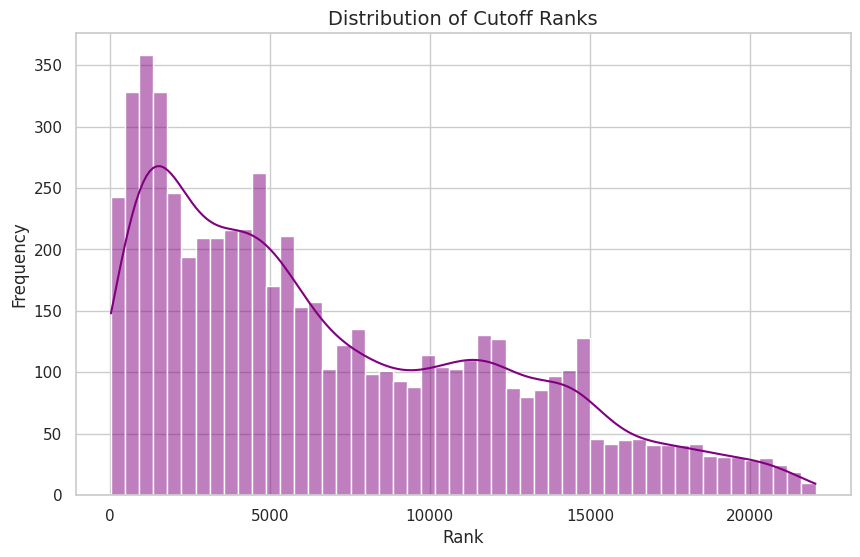

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter the dataset for ranks
rank_data = df[df['figure_kind'] == 'rank']

print("=== Rank Distribution Summary ===")
print(rank_data['figure'].describe())

# Plot the rank distribution
if not rank_data.empty:
    plt.figure(figsize=(10, 6))
    sns.histplot(data=rank_data, x='figure', kde=True, bins=50, color='purple')
    plt.title('Distribution of Cutoff Ranks', fontsize=14)
    plt.xlabel('Rank', fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.show()
else:
    print("No rank data available to plot (figure_kind may not contain 'rank').")

=== Correlation Matrix ===
                year    figure  source_page
year         1.00000 -0.171940    -0.067320
figure      -0.17194  1.000000     0.216968
source_page -0.06732  0.216968     1.000000


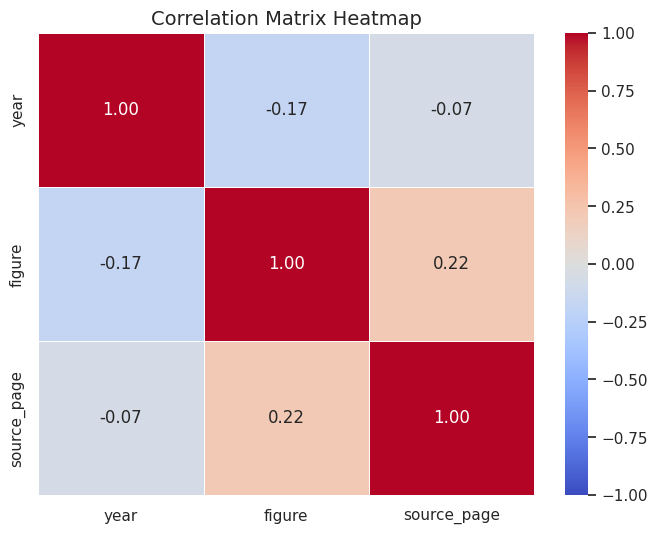

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns and compute correlation matrix
numeric_df = df.select_dtypes(include=['number'])
corr_matrix = numeric_df.corr()

print("=== Correlation Matrix ===")
print(corr_matrix)

# Plot the correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix Heatmap', fontsize=14)
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# 1. Prepare data and split
model_df = df.dropna(subset=['figure']).copy()
features = ['university_id', 'year', 'round', 'category', 'seat_type', 'figure_kind', 'basis']
target = 'figure'

X = model_df[features]
y = model_df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Define standard preprocessor
categorical_cols = ['university_id', 'round', 'category', 'seat_type', 'figure_kind', 'basis']
numeric_cols = ['year']

numerical_transformer = SimpleImputer(strategy='median')
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

# 3. Define the three models
models = {
    'Linear Regression': LinearRegression(n_jobs=-1),
    'Ridge Regression': Ridge(alpha=1.0, random_state=42),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=50, max_depth=15, random_state=42, n_jobs=-1)
}

# 4. Train and evaluate each model
results = {}
for name, regressor in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', regressor)
    ])

    print(f'Training {name}...')
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results[name] = {'MAE': mae, 'R2': r2}

# 5. Display comparison
print('\n=== Model Comparison Results ===')
for name, metrics in results.items():
    print(f"{name:25} -> MAE: {metrics['MAE']:.4f} | R2 Score: {metrics['R2']:.4f}")

Training Linear Regression...
Training Ridge Regression...
Training Random Forest Regressor...

=== Model Comparison Results ===
Linear Regression         -> MAE: 391.8402 | R2 Score: 0.7135
Ridge Regression          -> MAE: 391.8037 | R2 Score: 0.7136
Random Forest Regressor   -> MAE: 330.8195 | R2 Score: 0.7527


In [ ]:
import numpy as np
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# 1. Train a 'minimized' version of our pipeline (e.g., only using 'year' and 'figure_kind')
minimized_categorical_cols = ['figure_kind']
minimized_numeric_cols = ['year']

minimized_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, minimized_numeric_cols),
        ('cat', categorical_transformer, minimized_categorical_cols)
    ])

minimized_pipeline = Pipeline(steps=[
    ('preprocessor', minimized_preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=50, max_depth=15, random_state=42, n_jobs=-1))
])

# Train minimized model
minimized_pipeline.fit(X_train, y_train)

# 2. Get predictions from both full and minimized models
y_pred_full = model.predict(X_test)
y_pred_min = minimized_pipeline.predict(X_test)

# 3. Apply the 'Turing Test' via Kolmogorov-Smirnov test
# We check if the distribution of predictions from the minimized model is indistinguishable from the full model
statistic, p_value = ks_2samp(y_pred_full, y_pred_min)

print("=== Turing Test for Model Minimization ===")
print(f"KS Statistic: {statistic:.4f}")
print(f"p-value: {p_value:.4f}")

if p_value > 0.05:
    print("\nResult: PASS (The minimized model is indistinguishable from the full model at alpha=0.05)")
else:
    print("\nResult: FAIL (The minimized model's outputs are statistically distinguishable from the full model)")

=== Turing Test for Model Minimization ===
KS Statistic: 0.4151
p-value: 0.0000

Result: FAIL (The minimized model's outputs are statistically distinguishable from the full model)


In [ ]:
# Evaluate and print R-squared values for the trained models on testing data
print("=== Testing Data R-squared (R2) Scores ===")
for name, metrics in results.items():
    print(f"{name:25} -> R2 Score: {metrics['R2']:.6f}")

=== Testing Data R-squared (R2) Scores ===
Linear Regression         -> R2 Score: 0.713532
Ridge Regression          -> R2 Score: 0.713553
Random Forest Regressor   -> R2 Score: 0.752668


In [ ]:
print(f"{'Model Name':25} | {'Train R2':10} | {'Test R2':10}")
print("-" * 53)

for name, regressor in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', regressor)
    ])

    # Fit again to guarantee fresh evaluation metrics on training set
    pipeline.fit(X_train, y_train)

    train_preds = pipeline.predict(X_train)
    test_preds = pipeline.predict(X_test)

    train_r2 = r2_score(y_train, train_preds)
    test_r2 = r2_score(y_test, test_preds)

    print(f"{name:25} | {train_r2:.6f} | {test_r2:.6f}")
    #quanrize if the difference between the train and testing is more than 0.45

Model Name                | Train R2   | Test R2   
-----------------------------------------------------
Linear Regression         | 0.723016 | 0.713532
Ridge Regression          | 0.723015 | 0.713553
Random Forest Regressor   | 0.764643 | 0.752668
